# Convolution - Calculation with Example Function

> Part of *PHYS 0241: Biomedical Imaging* (Prof. Michael E. Durst, Middlebury College). The [textbook page for this notebook](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/python/ch05/ch05-07.html) shows the rendered version together with the pre-rendered animations (course password required).
>
> **Start here:** run the setup cell below first. In Google Colab, choose **File > Save a copy in Drive** to keep your changes.
>
> *Provided for academic use in PHYS 0241; please do not repost or redistribute ([terms of use](https://github.com/durstme/textbook-biomedicalimaging-notebooks/blob/main/LICENSE.md)).*

In [ ]:
# --- Setup: run this cell first.  It does nothing outside Google Colab. ---
import sys, os, importlib.util, urllib.request
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    # interactive matplotlib (%matplotlib widget) needs ipympl and Colab's custom widget manager
    if importlib.util.find_spec("ipympl") is None:
        get_ipython().run_line_magic("pip", "install -q ipympl")
        importlib.invalidate_caches()  # make the freshly installed package importable
        try:  # matplotlib caches its backend list on first use; refresh it so no restart is needed
            from matplotlib.backends.registry import backend_registry
            backend_registry._clear()
        except Exception:
            pass
    import ipympl  # noqa: F401
    from google.colab import output
    output.enable_custom_widget_manager()
    print("Colab setup done. If a %matplotlib widget cell still errors, use Runtime > Restart session, then Run all.")


Consider the two functions $f(t)$ and $g(t)$.

![Functions $f(t)$ and $g(t)$.](https://raw.githubusercontent.com/durstme/textbook-biomedicalimaging-notebooks/main/figures/ch05/ch05-07-example1.jpg)

In this example, our function $f(t)$ can be expressed as

$$
f(t)= \begin{cases} 2, & \text{for } 1 < t < 2 \\ 0, & \text{else} \end{cases}
$$

To find $g(t)$, we observe that the ramp is a line of slope $\mathrm{rise/run} = 2/5$ and a $y$-intercept of 0.  We can therefore express $g(t)$ as

$$
g(t)= \begin{cases} \frac{2}{5} t, & \text{for } 0 < t < 5 \\ 0, & \text{else} \end{cases}
$$


We want the convolution

$$
h(t) = (f \circledast g)(t) = \int_{-\infty}^{\infty} f(\tau)\,g(t-\tau)\,d\tau.
$$

where $\tau$ can be thought of as a delay.  To execute the integral, we need to change $g$ to be a function of delay to get $g(\tau)$, then reverse $g(\tau)$ to $g(-\tau)$, and shift it by $t$ to get $g(t-\tau)$. 

![Functions $f(\tau)$ and $g(t-\tau)$.](https://raw.githubusercontent.com/durstme/textbook-biomedicalimaging-notebooks/main/figures/ch05/ch05-07-example2.jpg)

Now, our function $f(\tau)$ can be expressed the same as before with $\tau$ substituted for $t$ as

$$
f(\tau)= \begin{cases} 2, & \text{for } 1 < \tau < 2 \\ 0, & \text{else} \end{cases}
$$

For $g(t-\tau)$, we can find the expression by simply swapping $\tau$ for $t$, but how do we expect the range as a function of $\tau$? The ramp is non-zero in the range $0<(t-\tau)<5$, which is equivalent to $(t-5)<\tau < t$. We can therefore express $g(t)$ as

$$
g(t-\tau)= \begin{cases} \frac{2}{5} (t-\tau), & \text{for } 0 < (t-\tau) < 5 \\ 0, & \text{else} \end{cases} = \begin{cases} -\frac{2}{5} \tau + \frac{2}{5} t, & \text{for } t-5 < \tau < t \\ 0, & \text{else} \end{cases}
$$



We sweep $g(t-\tau)$ across the square pulse $f(\tau)$, multiply them together, and find the area under the curve.

![Functions $f(\tau)$ and $g(t-\tau)$ on the same plot.](https://raw.githubusercontent.com/durstme/textbook-biomedicalimaging-notebooks/main/figures/ch05/ch05-07-example3.jpg)

### Regions

(i) $t<1$: No overlap.
(ii) $1<t<2$: Partial overlap.
(iii) $2<t<6$: Full overlap.  
(iv) $6<t<7$: Partial overlap.  
(v) $t>7$: No overlap.

### Case 1: no overlap ($t<1$)

![Case 1: no overlap ($t<1$)](https://raw.githubusercontent.com/durstme/textbook-biomedicalimaging-notebooks/main/figures/ch05/ch05-07-example4.jpg)

Because there is no overlap, the product is zero, and the integral is zero
$h(t) = \int_{-\infty}^{\infty} f(\tau) g(t-\tau) d\tau = 0$
for $t<1$.

### Case 2: partial overlap ($1<t<2$)

![Case 2: partial overlap ($1<t<2$)](https://raw.githubusercontent.com/durstme/textbook-biomedicalimaging-notebooks/main/figures/ch05/ch05-07-example5.jpg)

Then, the convolution integral becomes

$$
\begin{aligned}
h(t) &= \int_{-\infty}^{\infty} f(\tau) g(t-\tau) d\tau \\
&= \int_{1}^{t} 2\cdot \frac{2}{5}(t-\tau)\, d\tau \\
&= \frac{4}{5}\left(t\tau - \frac{\tau^{2}}{2}\right)\Big|_{\tau=1}^{\tau=t}\\
&= \frac{4}{5}\left[\frac{1}{2}t^2- \left(t-\frac{1}{2}\right)\right] = \frac{2}{5}t^{2}-\frac{4}{5}t+\frac{2}{5}.
\end{aligned}
$$


### Case 3: full overlap ($2<t<6$)

![Case 3: full overlap ($2<t<6$)](https://raw.githubusercontent.com/durstme/textbook-biomedicalimaging-notebooks/main/figures/ch05/ch05-07-example6.jpg)

Then, the convolution integral becomes

$$
\begin{aligned}
h(t) &= \int_{-\infty}^{\infty} f(\tau) g(t-\tau) d\tau \\
&= \int_{1}^{2} 2\cdot \frac{2}{5}(t-\tau)\, d\tau \\
&= \frac{4}{5}\left(t\tau - \frac{\tau^{2}}{2}\right)\Big|_{\tau=1}^{\tau=2}\\
&= \frac{4}{5}t-\frac{6}{5}.
\end{aligned}
$$


### Case 4: partial overlap ($6<t<7$)

![Case 4: partial overlap ($6<t<7$)](https://raw.githubusercontent.com/durstme/textbook-biomedicalimaging-notebooks/main/figures/ch05/ch05-07-example7.jpg)

Then, the convolution integral becomes

$$
\begin{aligned}
h(t) &= \int_{-\infty}^{\infty} f(\tau) g(t-\tau) d\tau \\
&= \int_{t-5}^{2} 2\cdot \frac{2}{5}(t-\tau)\, d\tau \\
&= \frac{4}{5}\left(t\tau - \frac{\tau^{2}}{2}\right)\Big|_{\tau=t-5}^{\tau=2}\\
&= \frac{4}{5}\left\{(2t-2)- \left[t(t-5)-\frac{1}{2}(t-5)^2\right]\right\} = -\frac{2}{5}t^2 + \frac{8}{5}t + \frac{42}{5}.
\end{aligned}
$$




### Case 5: no overlap ($t>7$)

![Case 5: no overlap ($t>7$)](https://raw.githubusercontent.com/durstme/textbook-biomedicalimaging-notebooks/main/figures/ch05/ch05-07-example8.jpg)

The convolution integral is zero.

## Complete solution

![Complete Solution](https://raw.githubusercontent.com/durstme/textbook-biomedicalimaging-notebooks/main/figures/ch05/ch05-07-example10.jpg)

Putting together all the cases, we have

$$
\begin{aligned}
h(t) &= \int_{-\infty}^{\infty} f(\tau) g(t-\tau) d\tau \\
&= \begin{cases} 0, & \text{for } t < 1 \\
\frac{2}{5}t^2 - \frac{4}{5}t + \frac{2}{5}, & \text{for } 1 < t < 2 \\
\frac{4}{5}t - \frac{6}{5}, & \text{for } 2 < t < 6 \\
-\frac{2}{5}t^2 + \frac{8}{5}t + \frac{42}{5}, & \text{for } 6 < t < 7 \\
0, & \text{for } t >7 \end{cases}
\end{aligned}
$$

Observe that this has a similar shape to the original ramp $g(t)$ but has been broadened by the convolution with the square pulse $f(t)$ of width 1.


## Import libraries

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
%matplotlib inline
# Define global "bold" style parameters
# This restores the thicker lines and fonts seen in older versions
plot_params = {
    # --- Fonts ---
    'font.size': 18,
    'font.family': 'sans-serif',
    'mathtext.fontset': 'stix',  # Use sans-serif for math text as well
    # --- Axes (The Box) ---
    'axes.linewidth': 1.0,       # Thicker box around the plot
    
    # --- Lines (The Signal) ---
    'lines.linewidth': 2.5,      # Thicker default plot lines
}

# Apply these settings globally
plt.rcParams.update(plot_params)

## Define parameters

In [3]:
# ==========================================
# 1. Define Functions
# ==========================================

def f0(t):
    """
    f0(t) = 2 for 1 <= t <= 2
    """
    return np.where((t >= 1) & (t <= 2), 2.0, 0.0)

def g0(t):
    """
    g0(t) = (2/5)*t for 0 <= t <= 5
    """
    return np.where((t >= 0) & (t <= 5), (2.0/5.0) * t, 0.0)

def g_shifted_array(t_array, tau_array):
    """
    Calculates g(t - tau) for ALL combinations of t and tau at once.
    
    t_array:   Shape (M,) -> Becomes (M, 1)
    tau_array: Shape (N,) -> Becomes (1, N)
    Result:    Shape (M, N)
    """
    # Broadcasting: (M, 1) - (1, N) = (M, N) matrix
    t_matrix = t_array[:, np.newaxis] 
    tau_matrix = tau_array[np.newaxis, :]
    
    # Apply g0 to the entire difference matrix
    return g0(t_matrix - tau_matrix)

def compute_convolution_vectorized(t_values, tau_grid):
    """
    Computes h(t) = integral f(tau) * g(t - tau) dtau using matrix operations.
    """
    # 1. Evaluate f(tau) -> Shape (N,)
    f_tau = f0(tau_grid)
    
    # 2. Evaluate g(t - tau) for all t -> Shape (M, N)
    g_shifted_matrix = g_shifted_array(t_values, tau_grid)
    
    # 3. Multiply f(tau) * g(t - tau) element-wise along rows
    # Broadcasting: (N,) * (M, N) -> (M, N)
    product_matrix = f_tau * g_shifted_matrix
    
    # 4. Integrate along the tau axis (axis 1)
    h_values = np.trapezoid(product_matrix, tau_grid, axis=1)
    
    return h_values

# ==========================================
# 2. Setup Grid and Compute
# ==========================================

# Define Grids
# tau: Integration variable (needs high resolution)
tau = np.linspace(0, 3, 1000) 

# t: Time points to evaluate result at
t_range = np.linspace(0, 9, 500)


## Plot functions $f(t)$ and $g(t)$ separately

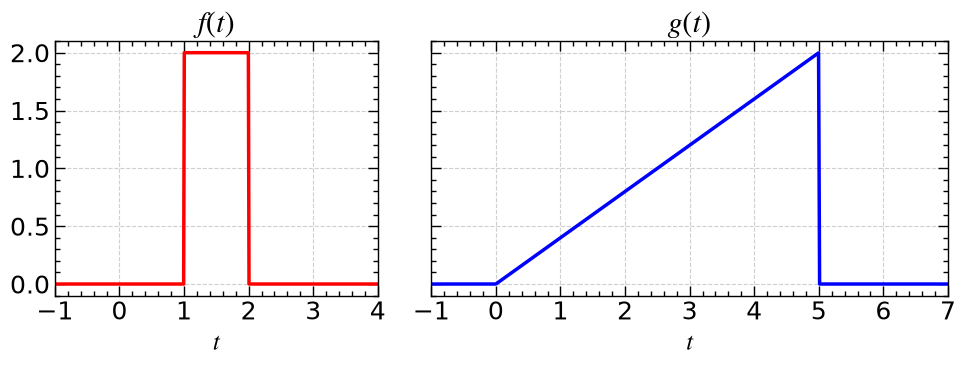

In [4]:
# ==========================================
# 3. Plotting with Equal Scaling
# ==========================================

x_min_f1, x_max_f1 = -1, 4 # x range for f0(t)
x_min_g1, x_max_g1 = -1, 7 # x range for g0(t)

t_f1 = np.linspace(x_min_f1, x_max_f1, 500)
t_g1 = np.linspace(x_min_g1, x_max_g1, 500)

range_f1 = x_max_f1 - x_min_f1
range_g1 = x_max_g1 - x_min_g1

f_ticks1 = np.arange(np.ceil(x_min_f1), np.floor(x_max_f1) + 1, 1).astype(int)
g_ticks1 = np.arange(np.ceil(x_min_g1), np.floor(x_max_g1) + 1, 1).astype(int)

fig1, (ax11, ax12) = plt.subplots(1, 2, figsize=(10, 4), 
                               gridspec_kw={'width_ratios': [range_f1, range_g1]},
                               sharey=True)

# Plot f(t)
ax11.plot(t_f1, f0(t_f1), 'r', linewidth=2.5)
ax11.set_title(r"$f(t)$")
ax11.set_xlabel(r"$t$")
ax11.set_xlim(x_min_f1, x_max_f1)
ax11.grid(True, linestyle='--', alpha=0.6)
ax11.minorticks_on()
ax11.tick_params(which='both',direction="in",width=1)
ax11.tick_params(which='major',length=7)
ax11.tick_params(which='minor',length=3.5)
ax11.xaxis.set_ticks_position('both')
ax11.yaxis.set_ticks_position('both')
ax11.set_xticks(f_ticks1)

# Plot g(t)
ax12.plot(t_g1, g0(t_g1), 'b', linewidth=2.5)
ax12.set_title(r"$g(t)$")
ax12.set_xlabel(r"$t$")
ax12.set_xlim(x_min_g1, x_max_g1)
ax12.grid(True, linestyle='--', alpha=0.6)
ax12.minorticks_on()
ax12.tick_params(which='both',direction="in",width=1)
ax12.tick_params(which='major',length=7)
ax12.tick_params(which='minor',length=3.5)
ax12.xaxis.set_ticks_position('both')
ax12.yaxis.set_ticks_position('both')
ax12.set_xticks(g_ticks1)

plt.tight_layout()
plt.show()
# fig1.savefig("../figures/ch05/ch05-07-example1.jpg", dpi=300, bbox_inches='tight')

## Plot functions $f(\tau)$ and $g(t-\tau)$ separately

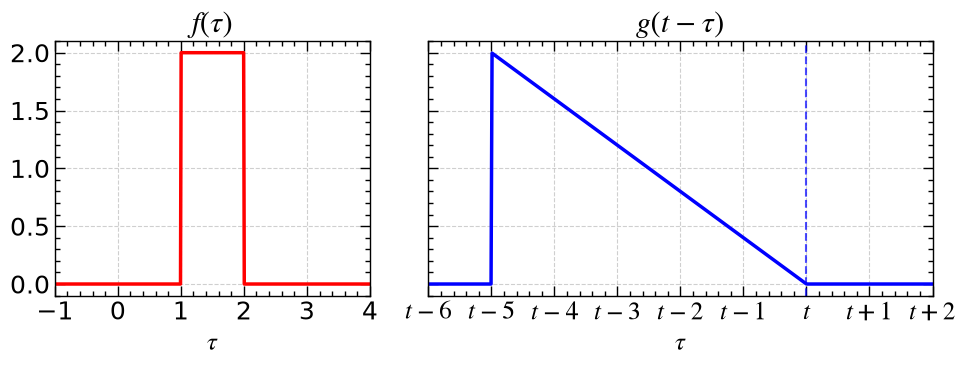

In [5]:
# ==========================================
# 3. Plotting with Equal Scaling
# ==================

t2 = -5

x_min_f2, x_max_f2 = -1, 4 # x range for f0(tau)
x_min_g2, x_max_g2 = t2-6, t2+2 # x range for g0(t-tau)

tau_f2 = np.linspace(x_min_f2, x_max_f2, 500)
tau_g2 = np.linspace(x_min_g2, x_max_g2, 500)

range_f2 = x_max_f2 - x_min_f2
range_g2 = x_max_g2 - x_min_g2

f_ticks2 = np.arange(np.ceil(x_min_f2), np.floor(x_max_f2) + 1, 1).astype(int) # Define tick positions at every integer within the plot range
g_ticks2 = np.arange(np.ceil(x_min_g2), np.floor(x_max_g2) + 1, 1).astype(int)

fig2, (ax21, ax22) = plt.subplots(1, 2, figsize=(10, 4), 
                               gridspec_kw={'width_ratios': [range_f2, range_g2]},
                               sharey=True)

# Plot f(t)
ax21.plot(tau_f2, f0(tau_f2), 'r', linewidth=2.5)
ax21.set_title(r"$f(\tau)$")
ax21.set_xlabel(r"$\tau$")
ax21.set_xlim(x_min_f2, x_max_f2)
ax21.grid(True, linestyle='--', alpha=0.6)
ax21.minorticks_on()
ax21.tick_params(which='both',direction="in",width=1)
ax21.tick_params(which='major',length=7)
ax21.tick_params(which='minor',length=3.5)
ax21.xaxis.set_ticks_position('both')
ax21.yaxis.set_ticks_position('both')
ax21.set_xticks(f_ticks2)

# Plot g(t)
ax22.plot(tau_g2, g0(t2-tau_g2), 'b', linewidth=2.5)
ax22.axvline(x=t2, color='b', linestyle='--', linewidth=1.5, alpha=0.7)
ax22.set_title(r"$g(t-\tau)$")
ax22.set_xlabel(r"$\tau$")
ax22.set_xlim(x_min_g2, x_max_g2)
ax22.grid(True, linestyle='--', alpha=0.6)
ax22.minorticks_on()
ax22.tick_params(which='both',direction="in",width=1)
ax22.tick_params(which='major',length=7)
ax22.tick_params(which='minor',length=3.5)
ax22.xaxis.set_ticks_position('both')
ax22.yaxis.set_ticks_position('both')
ax22.set_xticks(g_ticks2)

# 2. Generate labels relative to t2
labels2 = []
for val in g_ticks2:
    diff = int(val - t2)
    if diff == 0:
        labels2.append(r"$t$")        # at tau = t
    elif diff < 0:
        labels2.append(rf"$t - {abs(diff)}$") # e.g., t - 1
    else:
        labels2.append(rf"$t + {diff}$")      # e.g., t + 1

# 3. Apply the custom labels
ax22.set_xticklabels(labels2)

plt.tight_layout()
plt.show()

# fig2.savefig("../figures/ch05/ch05-07-example2.jpg", dpi=300, bbox_inches='tight')

## Plot functions $f(\tau)$ and $g(t-\tau)$ together

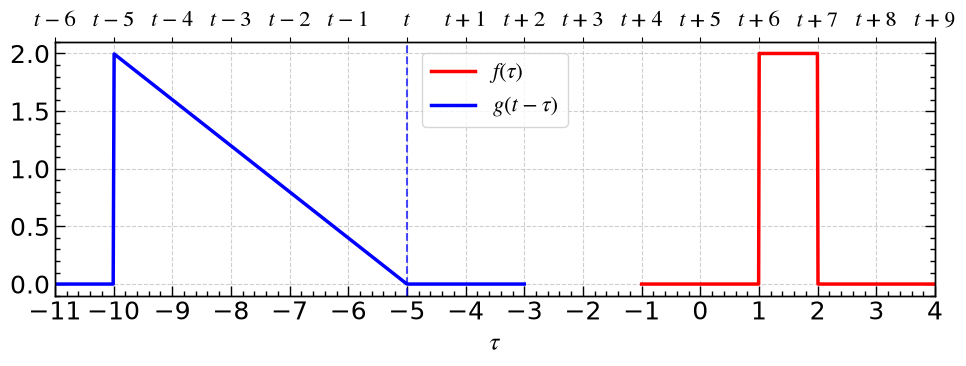

In [6]:
# ==========================================
# 3. Plotting with Equal Scaling
# ==================

t3 = -5

x_min_f3, x_max_f3 = -1, 4 # x range for f0(tau)
x_min_g3, x_max_g3 = t3-6, t3+2 # x range for g0(t-tau)
xmin3 = np.min([x_min_f3, x_min_g3])
xmax3 = np.max([x_max_f3, x_max_g3])

tau_f3 = np.linspace(x_min_f3, x_max_f3, 500)
tau_g3 = np.linspace(x_min_g3, x_max_g3, 500)

range_f3 = x_max_f3 - x_min_f3
range_g3 = x_max_g3 - x_min_g3

f_ticks3 = np.arange(np.ceil(x_min_f3), np.floor(x_max_f3) + 1, 1).astype(int) # Define tick positions at every integer within the plot range
g_ticks3 = np.arange(np.ceil(x_min_g3), np.floor(x_max_g3) + 1, 1).astype(int)

fig3, ax3 = plt.subplots(figsize=(10, 4))

# Plot f(t)
ax3.plot(tau_f3, f0(tau_f3), 'r', linewidth=2.5, label=r"$f(\tau)$")
ax3.plot(tau_g3, g0(t3 - tau_g3), 'b', linewidth=2.5, label=r"$g(t-\tau)$")
ax3.axvline(x=t3, color='b', linestyle='--', linewidth=1.5, alpha=0.7)
ax3.set_xlabel(r"$\tau$")
ax3.set_xlim(xmin3, xmax3)
ax3.grid(True, linestyle='--', alpha=0.6)
ax3.minorticks_on()
ax3.tick_params(which='both',direction="in",width=1)
ax3.tick_params(which='major',length=7)
ax3.tick_params(which='minor',length=3.5)
ax3.xaxis.set_ticks_position('both')
ax3.yaxis.set_ticks_position('both')
ax3.legend(fontsize=16, loc='upper center')

valid_ticks3 = np.arange(xmin3, xmax3+1, 1)
ax3.set_xticks(valid_ticks3)

ax32 = ax3.twiny()  # Create a second x-axis on top
ax32.set_xlim(ax3.get_xlim())  # Ensure the top axis has the same limits as the bottom axis
# 2. Generate labels (t, t-1, etc.)
labels3 = []
for val in valid_ticks3:
    diff2 = int(val - t3) # val = t3 + diff2  -> diff2 = val - t3
    if diff2 == 0:
        labels3.append(r"$t$")
    elif diff2 < 0:
        labels3.append(rf"$t - {abs(diff2)}$")
    else:
        labels3.append(rf"$t + {diff2}$")

ax32.set_xticks(valid_ticks3)
ax32.set_xticklabels(labels3, fontsize=16)

# Optional: Move the top axis spine down slightly if it feels too high, 
# or keep it standard. Here we keep standard.

# plt.title(f"Convolution Overlap at $t={t3}$", y=1.15, fontsize=16)
plt.tight_layout()
plt.show()

# fig3.savefig("../figures/ch05/ch05-07-example3.jpg", dpi=300, bbox_inches='tight')

## Case 1: No overlap ($t<1$)

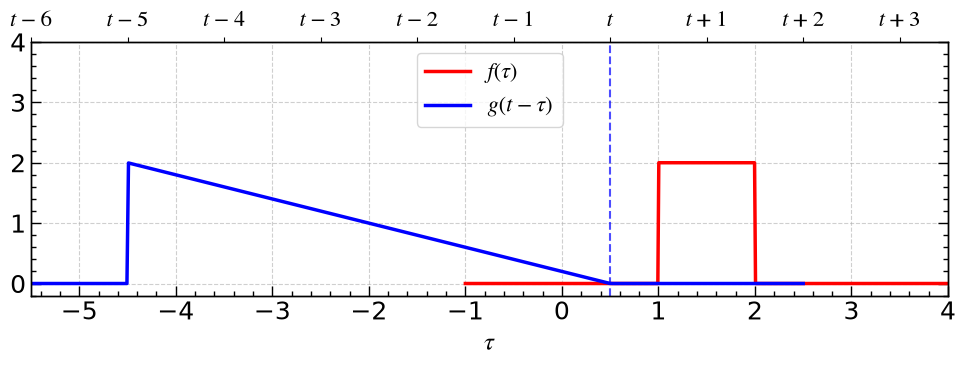

In [7]:
# ==========================================
# 3. Plotting with Equal Scaling
# ==================

t4 = 0.5

x_min_f4, x_max_f4 = -1, 4 # x range for f0(tau)
x_min_g4, x_max_g4 = t4-6, t4+2 # x range for g0(t-tau)
xmin4 = np.min([x_min_f4, x_min_g4])
xmax4 = np.max([x_max_f4, x_max_g4])

tau_f4 = np.linspace(x_min_f4, x_max_f4, 500)
tau_g4 = np.linspace(x_min_g4, x_max_g4, 500)

range_f4 = x_max_f4 - x_min_f4
range_g4 = x_max_g4 - x_min_g4

f_ticks4 = np.arange(np.ceil(x_min_f4), np.floor(x_max_f4) + 1, 1).astype(int) # Define tick positions at every integer within the plot range
g_ticks4 = np.arange(np.ceil(x_min_g4), np.floor(x_max_g4) + 1, 1).astype(int)

fig4, ax4 = plt.subplots(figsize=(10, 4))

# Plot f(t)
ax4.plot(tau_f4, f0(tau_f4), 'r', linewidth=2.5, label=r"$f(\tau)$")
ax4.plot(tau_g4, g0(t4 - tau_g4), 'b', linewidth=2.5, label=r"$g(t-\tau)$")
ax4.axvline(x=t4, color='b', linestyle='--', linewidth=1.5, alpha=0.7)
ax4.set_xlabel(r"$\tau$")
ax4.set_xlim(xmin4, xmax4)
ax4.set_ylim(-0.2, 4)
ax4.grid(True, linestyle='--', alpha=0.6)
ax4.minorticks_on()
ax4.tick_params(which='both',direction="in",width=1)
ax4.tick_params(which='major',length=7)
ax4.tick_params(which='minor',length=3.5)
ax4.xaxis.set_ticks_position('both')
ax4.yaxis.set_ticks_position('both')
ax4.legend(fontsize=16, loc='upper center')

ticks4_bottom = np.arange(np.ceil(xmin4), np.floor(xmax4) + 1, 1).astype(int)
ax4.set_xticks(ticks4_bottom)

ax42 = ax4.twiny()  # Create a second x-axis on top
ax42.set_xlim(ax4.get_xlim())  # Ensure the top axis has the same limits as the bottom axis

valid_offsets4 = np.arange(np.ceil(xmin4-t4), np.floor(xmax4-t4) + 1, 1).astype(int)
valid_ticks_top4 = valid_offsets4 + t4

# 2. Set the ticks and labels
ax42.set_xticks(valid_ticks_top4)

labels4 = []
for offset4 in valid_offsets4:
    if offset4 == 0:
        labels4.append(r"$t$")
    elif offset4 < 0:
        labels4.append(rf"$t - {abs(int(offset4))}$")
    else:
        labels4.append(rf"$t + {int(offset4)}$")

ax42.set_xticks(valid_ticks_top4)
ax42.set_xticklabels(labels4, fontsize=16)

# Optional: Move the top axis spine down slightly if it feels too high, 
# or keep it standard. Here we keep standard.

# plt.title(f"Convolution Overlap at $t={t4}$", y=1.15, fontsize=16)
plt.tight_layout()
plt.show()

# fig4.savefig("../figures/ch05/ch05-07-example4.jpg", dpi=300, bbox_inches='tight')

## Case 2: Partial overlap ($1<t<2$)

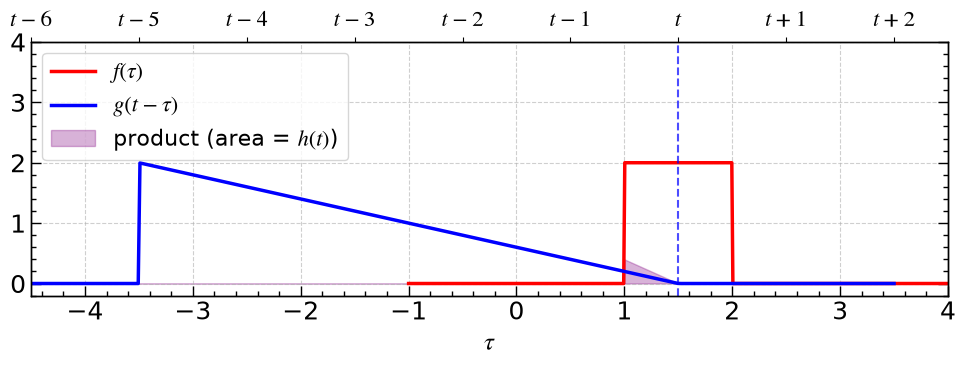

In [8]:
# ==========================================
# 3. Plotting with Equal Scaling
# ==================

t5 = 1.5

x_min_f5, x_max_f5 = -1, 4 # x range for f0(tau)
x_min_g5, x_max_g5 = t5-6, t5+2 # x range for g0(t-tau)
xmin5 = np.min([x_min_f5, x_min_g5])
xmax5 = np.max([x_max_f5, x_max_g5])

tau_f5 = np.linspace(x_min_f5, x_max_f5, 500)
tau_g5 = np.linspace(x_min_g5, x_max_g5, 500)
tau_common5 = np.linspace(xmin5, xmax5, 2000)

range_f5 = x_max_f5 - x_min_f5
range_g5 = x_max_g5 - x_min_g5

f_ticks5 = np.arange(np.ceil(x_min_f5), np.floor(x_max_f5) + 1, 1).astype(int) # Define tick positions at every integer within the plot range
g_ticks5 = np.arange(np.ceil(x_min_g5), np.floor(x_max_g5) + 1, 1).astype(int)

fig5, ax5 = plt.subplots(figsize=(10, 4))

# Plot f(t)
ax5.plot(tau_f5, f0(tau_f5), 'r', linewidth=2.5, label=r"$f(\tau)$")
ax5.plot(tau_g5, g0(t5 - tau_g5), 'b', linewidth=2.5, label=r"$g(t-\tau)$")
ax5.axvline(x=t5, color='b', linestyle='--', linewidth=1.5, alpha=0.7)

product5 = f0(tau_common5) * g0(t5 - tau_common5)
ax5.fill_between(tau_common5, product5, color='purple', alpha=0.3, label=r'product (area = $h(t)$)')


ax5.set_xlabel(r"$\tau$")
ax5.set_xlim(xmin5, xmax5)
ax5.set_ylim(-0.2, 4)
ax5.grid(True, linestyle='--', alpha=0.6)
ax5.minorticks_on()
ax5.tick_params(which='both',direction="in",width=1)
ax5.tick_params(which='major',length=7)
ax5.tick_params(which='minor',length=3.5)
ax5.xaxis.set_ticks_position('both')
ax5.yaxis.set_ticks_position('both')
ax5.legend(fontsize=16, loc='upper left')

ticks5_bottom = np.arange(np.ceil(xmin5), np.floor(xmax5) + 1, 1).astype(int)
ax5.set_xticks(ticks5_bottom)

ax52 = ax5.twiny()  # Create a second x-axis on top
ax52.set_xlim(ax5.get_xlim())  # Ensure the top axis has the same limits as the bottom axis

valid_offsets5 = np.arange(np.ceil(xmin5-t5), np.floor(xmax5-t5) + 1, 1).astype(int)
valid_ticks_top5 = valid_offsets5 + t5

# 2. Set the ticks and labels
ax52.set_xticks(valid_ticks_top5)

labels5 = []
for offset5 in valid_offsets5:
    if offset5 == 0:
        labels5.append(r"$t$")
    elif offset5 < 0:
        labels5.append(rf"$t - {abs(int(offset5))}$")
    else:
        labels5.append(rf"$t + {int(offset5)}$")

ax52.set_xticks(valid_ticks_top5)
ax52.set_xticklabels(labels5, fontsize=16)

# Optional: Move the top axis spine down slightly if it feels too high, 
# or keep it standard. Here we keep standard.

# plt.title(f"Convolution Overlap at $t={t5}$", y=1.15, fontsize=16)
plt.tight_layout()
plt.show()

# fig5.savefig("../figures/ch05/ch05-07-example5.jpg", dpi=300, bbox_inches='tight')

## Case 3: Full Overlap ($2<t<6$)

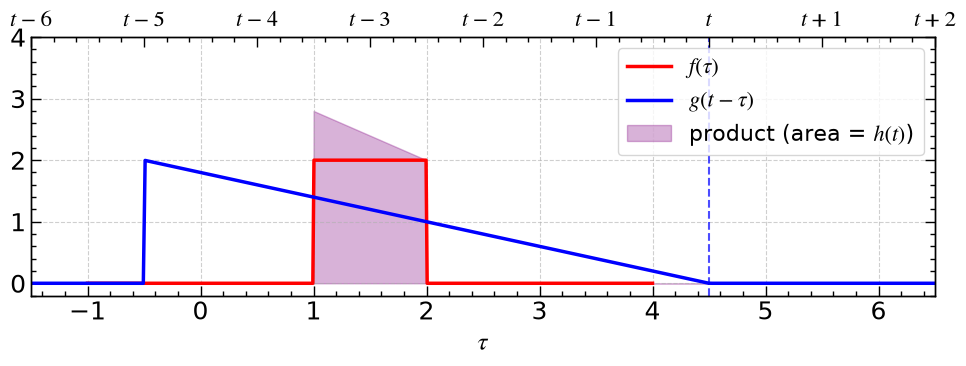

In [9]:
# ==========================================
# 3. Plotting with Equal Scaling
# ==================

t6 = 4.5

x_min_f6, x_max_f6 = -1, 4 # x range for f0(tau)
x_min_g6, x_max_g6 = t6-6, t6+2 # x range for g0(t-tau)
xmin6 = np.min([x_min_f6, x_min_g6])
xmax6 = np.max([x_max_f6, x_max_g6])

tau_f6 = np.linspace(x_min_f6, x_max_f6, 500)
tau_g6 = np.linspace(x_min_g6, x_max_g6, 500)
tau_common6 = np.linspace(xmin6, xmax6, 2000)

range_f6 = x_max_f6 - x_min_f6
range_g6 = x_max_g6 - x_min_g6

f_ticks6 = np.arange(np.ceil(x_min_f6), np.floor(x_max_f6) + 1, 1).astype(int) # Define tick positions at every integer within the plot range
g_ticks6 = np.arange(np.ceil(x_min_g6), np.floor(x_max_g6) + 1, 1).astype(int)

fig6, ax6 = plt.subplots(figsize=(10, 4))

# Plot f(t)
ax6.plot(tau_f6, f0(tau_f6), 'r', linewidth=2.5, label=r"$f(\tau)$")
ax6.plot(tau_g6, g0(t6 - tau_g6), 'b', linewidth=2.5, label=r"$g(t-\tau)$")
ax6.axvline(x=t6, color='b', linestyle='--', linewidth=1.5, alpha=0.7)

product6 = f0(tau_common6) * g0(t6 - tau_common6)
ax6.fill_between(tau_common6, product6, color='purple', alpha=0.3, label=r'product (area = $h(t)$)')


ax6.set_xlabel(r"$\tau$")
ax6.set_xlim(xmin6, xmax6)
ax6.set_ylim(-0.2, 4)
ax6.grid(True, linestyle='--', alpha=0.6)
ax6.minorticks_on()
ax6.tick_params(which='both',direction="in",width=1)
ax6.tick_params(which='major',length=7)
ax6.tick_params(which='minor',length=3.5)
ax6.xaxis.set_ticks_position('both')
ax6.yaxis.set_ticks_position('both')
ax6.legend(fontsize=16, loc='upper right')

ticks6_bottom = np.arange(np.ceil(xmin6), np.floor(xmax6) + 1, 1).astype(int)
ax6.set_xticks(ticks6_bottom)

ax62 = ax6.twiny()  # Create a second x-axis on top
ax62.set_xlim(ax6.get_xlim())  # Ensure the top axis has the same limits as the bottom axis

valid_offsets6 = np.arange(np.ceil(xmin6-t6), np.floor(xmax6-t6) + 1, 1).astype(int)
valid_ticks_top6 = valid_offsets6 + t6

# 2. Set the ticks and labels
ax62.set_xticks(valid_ticks_top6)

labels6 = []
for offset6 in valid_offsets6:
    if offset6 == 0:
        labels6.append(r"$t$")
    elif offset6 < 0:
        labels6.append(rf"$t - {abs(int(offset6))}$")
    else:
        labels6.append(rf"$t + {int(offset6)}$")

ax62.set_xticklabels(labels6, fontsize=16)

# Apply tick styling to top axis as well
ax62.minorticks_on()
ax62.tick_params(which='both', direction="in", width=1)
ax62.tick_params(which='major', length=7)
ax62.tick_params(which='minor', length=3.5)

# plt.title(f"Convolution Overlap at $t={t6}$", y=1.15, fontsize=16)
plt.tight_layout()
plt.show()

# fig6.savefig("../figures/ch05/ch05-07-example6.jpg", dpi=300, bbox_inches='tight')

## Case 4: Partial Overlap ($6<t<7$)

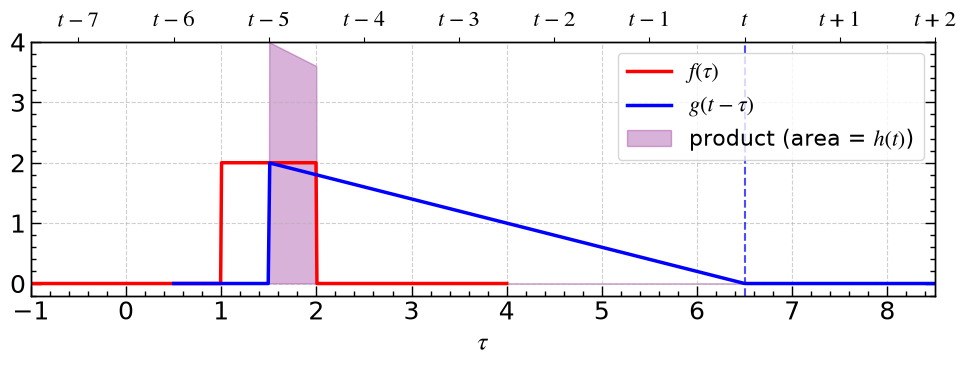

In [10]:
# ==========================================
# 3. Plotting with Equal Scaling
# ==================

t7 = 6.5

x_min_f7, x_max_f7 = -1, 4 # x range for f0(tau)
x_min_g7, x_max_g7 = t7-6, t7+2 # x range for g0(t-tau)
xmin7 = np.min([x_min_f7, x_min_g7])
xmax7 = np.max([x_max_f7, x_max_g7])

tau_f7 = np.linspace(x_min_f7, x_max_f7, 500)
tau_g7 = np.linspace(x_min_g7, x_max_g7, 500)
tau_common7 = np.linspace(xmin7, xmax7, 2000)

range_f7 = x_max_f7 - x_min_f7
range_g7 = x_max_g7 - x_min_g7

f_ticks7 = np.arange(np.ceil(x_min_f7), np.floor(x_max_f7) + 1, 1).astype(int) # Define tick positions at every integer within the plot range
g_ticks7 = np.arange(np.ceil(x_min_g7), np.floor(x_max_g7) + 1, 1).astype(int)

fig7, ax7 = plt.subplots(figsize=(10, 4))

# Plot f(t)
ax7.plot(tau_f7, f0(tau_f7), 'r', linewidth=2.5, label=r"$f(\tau)$")
ax7.plot(tau_g7, g0(t7 - tau_g7), 'b', linewidth=2.5, label=r"$g(t-\tau)$")
ax7.axvline(x=t7, color='b', linestyle='--', linewidth=1.5, alpha=0.7)

product7 = f0(tau_common7) * g0(t7 - tau_common7)
ax7.fill_between(tau_common7, product7, color='purple', alpha=0.3, label=r'product (area = $h(t)$)')


ax7.set_xlabel(r"$\tau$")
ax7.set_xlim(xmin7, xmax7)
ax7.set_ylim(-0.2, 4)
ax7.grid(True, linestyle='--', alpha=0.6)
ax7.minorticks_on()
ax7.tick_params(which='both',direction="in",width=1)
ax7.tick_params(which='major',length=7)
ax7.tick_params(which='minor',length=3.5)
ax7.xaxis.set_ticks_position('both')
ax7.yaxis.set_ticks_position('both')
ax7.legend(fontsize=16, loc='upper right')

ticks7_bottom = np.arange(np.ceil(xmin7), np.floor(xmax7) + 1, 1).astype(int)
ax7.set_xticks(ticks7_bottom)

ax72 = ax7.twiny()  # Create a second x-axis on top
ax72.set_xlim(ax7.get_xlim())  # Ensure the top axis has the same limits as the bottom axis

valid_offsets7 = np.arange(np.ceil(xmin7-t7), np.floor(xmax7-t7) + 1, 1).astype(int)
valid_ticks_top7 = valid_offsets7 + t7

# 2. Set the ticks and labels
ax72.set_xticks(valid_ticks_top7)

labels7 = []
for offset7 in valid_offsets7:
    if offset7 == 0:
        labels7.append(r"$t$")
    elif offset7 < 0:
        labels7.append(rf"$t - {abs(int(offset7))}$")
    else:
        labels7.append(rf"$t + {int(offset7)}$")

ax72.set_xticks(valid_ticks_top7)
ax72.set_xticklabels(labels7, fontsize=16)
# ax72.tick_params(which='both',direction="in",width=1)
# ax72.tick_params(which='major',length=7)
# ax72.tick_params(which='minor',length=3.5)

# Optional: Move the top axis spine down slightly if it feels too high, 
# or keep it standard. Here we keep standard.

# plt.title(f"Convolution Overlap at $t={t7}$", y=1.15, fontsize=16)
plt.tight_layout()
plt.show()

# fig7.savefig("../figures/ch05/ch05-07-example7.jpg", dpi=300, bbox_inches='tight')

## Case 5: No overlap ($t>7$)

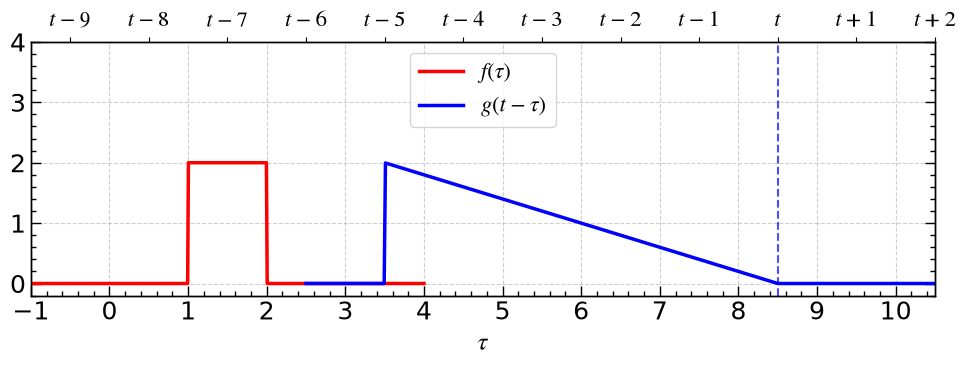

In [11]:
# ==========================================
# 3. Plotting with Equal Scaling
# ==================

t8 = 8.5

x_min_f8, x_max_f8 = -1, 4 # x range for f0(tau)
x_min_g8, x_max_g8 = t8-6, t8+2 # x range for g0(t-tau)
xmin8 = np.min([x_min_f8, x_min_g8])
xmax8 = np.max([x_max_f8, x_max_g8])

tau_f8 = np.linspace(x_min_f8, x_max_f8, 500)
tau_g8 = np.linspace(x_min_g8, x_max_g8, 500)

range_f8 = x_max_f8 - x_min_f8
range_g8 = x_max_g8 - x_min_g8

f_ticks8 = np.arange(np.ceil(x_min_f8), np.floor(x_max_f8) + 1, 1).astype(int) # Define tick positions at every integer within the plot range
g_ticks8 = np.arange(np.ceil(x_min_g8), np.floor(x_max_g8) + 1, 1).astype(int)

fig8, ax8 = plt.subplots(figsize=(10, 4))

# Plot f(t)
ax8.plot(tau_f8, f0(tau_f8), 'r', linewidth=2.5, label=r"$f(\tau)$")
ax8.plot(tau_g8, g0(t8 - tau_g8), 'b', linewidth=2.5, label=r"$g(t-\tau)$")
ax8.axvline(x=t8, color='b', linestyle='--', linewidth=1.5, alpha=0.7)
ax8.set_xlabel(r"$\tau$")
ax8.set_xlim(xmin8, xmax8)
ax8.set_ylim(-0.2, 4)
ax8.grid(True, linestyle='--', alpha=0.6)
ax8.minorticks_on()
ax8.tick_params(which='both',direction="in",width=1)
ax8.tick_params(which='major',length=7)
ax8.tick_params(which='minor',length=3.5)
ax8.xaxis.set_ticks_position('both')
ax8.yaxis.set_ticks_position('both')
ax8.legend(fontsize=16, loc='upper center')

ticks8_bottom = np.arange(np.ceil(xmin8), np.floor(xmax8) + 1, 1).astype(int)
ax8.set_xticks(ticks8_bottom)

ax82 = ax8.twiny()  # Create a second x-axis on top
ax82.set_xlim(ax8.get_xlim())  # Ensure the top axis has the same limits as the bottom axis

valid_offsets8 = np.arange(np.ceil(xmin8-t8), np.floor(xmax8-t8) + 1, 1).astype(int)
valid_ticks_top8 = valid_offsets8 + t8

# 2. Set the ticks and labels
ax82.set_xticks(valid_ticks_top8)

labels8 = []
for offset8 in valid_offsets8:
    if offset8 == 0:
        labels8.append(r"$t$")
    elif offset8 < 0:
        labels8.append(rf"$t - {abs(int(offset8))}$")
    else:
        labels8.append(rf"$t + {int(offset8)}$")

ax82.set_xticks(valid_ticks_top8)
ax82.set_xticklabels(labels8, fontsize=16)

# Optional: Move the top axis spine down slightly if it feels too high, 
# or keep it standard. Here we keep standard.

# plt.title(f"Convolution Overlap at $t={t8}$", y=1.15, fontsize=16)
plt.tight_layout()
plt.show()

# fig8.savefig("../figures/ch05/ch05-07-example8.jpg", dpi=300, bbox_inches='tight')

## Make interactive with ipywidgets

In [12]:
%matplotlib widget
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon
import ipywidgets as widgets
from IPython.display import display

# ==========================================
# 1. Define Functions
# ==========================================
def f0_2(t):
    return np.where((t >= 1) & (t <= 2), 2.0, 0.0)

def g0_2(t):
    return np.where((t >= 0) & (t <= 5), (2.0/5.0) * t, 0.0)

# ==========================================
# 2. Setup Figure & Axes
# ==========================================
plt.ioff()
fig, ax = plt.subplots(figsize=(9, 5))
fig.canvas.header_visible = False
fig.canvas.footer_visible = False

# Ranges
x_min, x_max = -5, 8
tau2 = np.linspace(x_min, x_max, 1000)

# --- Plot Static Elements ---
ax.plot(tau2, f0_2(tau2), 'r', linewidth=2.5, label=r"$f(\tau)$")

# --- Initialize Dynamic Elements ---
line_g, = ax.plot([], [], 'b', linewidth=2.5, label=r"$g(t-\tau)$")
line_v = ax.axvline(x=0, color='k', linestyle='--', linewidth=1.5, alpha=0.7)
fill_collection = ax.fill_between([], [], color='purple', alpha=0.3) 

# --- Configure Primary Axis (Bottom) ---
ax.set_xlim(x_min, x_max)
ax.set_ylim(-0.5, 4)
ax.set_xlabel(r"$\tau$ (Integration Variable)")
ax.grid(True, linestyle='--', alpha=0.6)
ax.legend(loc='upper right', fontsize=16)

# Static Integer Ticks for Bottom
ticks_bottom = np.arange(np.ceil(x_min), np.floor(x_max) + 1, 1).astype(int)
ax.set_xticks(ticks_bottom)

# --- Apply Custom Tick Settings (Bottom) ---
ax.minorticks_on()
ax.tick_params(which='both', direction="in", width=1)
ax.tick_params(which='major', length=7)
ax.tick_params(which='minor', length=3.5)
ax.yaxis.set_ticks_position('both') 
ax.xaxis.set_ticks_position('bottom') 

# --- Configure Secondary Axis (Top) ---
ax_top = ax.twiny()
ax_top.set_xlim(x_min, x_max)
# ax_top.set_xlabel(r"Relative Shift ($t-\tau2$)", labelpad=10)

# Apply same tick styling to top axis
ax_top.minorticks_on()
ax_top.tick_params(which='both', direction="in", width=1)
ax_top.tick_params(which='major', length=7)
ax_top.tick_params(which='minor', length=3.5)

# ==========================================
# 3. Update Function
# ==========================================
def update_plot(change):
    t = change['new']
    
    # 1. Update g(t-tau2) Line
    y_g_shifted = g0_2(t - tau2)
    line_g.set_data(tau2, y_g_shifted)
    
    # 2. Update Vertical Line (The "Front" of the wave)
    if x_min <= t <= x_max:
        line_v.set_xdata([t])
        line_v.set_visible(True)
    else:
        line_v.set_visible(False)
        
    # 3. Update Shading
    global fill_collection
    fill_collection.remove()
    product = f0_2(tau2) * y_g_shifted
    fill_collection = ax.fill_between(tau2, product, color='purple', alpha=0.3)

    # 4. Update Top Ticks (Relative to t)
    # ---------------------------------------------------------
    # Create offsets: -10, -9, ..., 0, ..., 10 relative to t
    offsets = np.arange(-10, 11, 1)
    
    # Calculate exact tick positions (floats)
    potential_ticks = t + offsets
    
    # Filter for visible range
    mask = (potential_ticks >= x_min) & (potential_ticks <= x_max)
    valid_ticks = potential_ticks[mask]
    valid_offsets = offsets[mask]
    
    ax_top.set_xticks(valid_ticks)
    
    labels = []
    for offset in valid_offsets:
        if offset == 0: labels.append(r"$t$")
        elif offset < 0: labels.append(rf"$t - {abs(int(offset))}$")
        else: labels.append(rf"$t + {int(offset)}$")
            
    ax_top.set_xticklabels(labels)
    # ---------------------------------------------------------

    # ax.set_title(f"Convolution: $t = {t:.2f}$", fontsize=14, y=1.12)
    
    fig.canvas.draw_idle()

# ==========================================
# 4. Create Slider
# ==========================================
slider = widgets.FloatSlider(
    value=1.5, min=-1.0, max=8.0, step=0.05, 
    description='t:', layout=widgets.Layout(width='600px')
)

slider.observe(update_plot, names='value')

# Trigger initial update
update_plot({'new': slider.value})

# Display
layout = widgets.VBox([slider, fig.canvas])
display(layout)

### Save animation as mp4 movie file

In [13]:
%matplotlib widget
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from matplotlib.patches import Polygon

# ==========================================
# 1. Define Functions
# ==========================================
def f0_9(t):
    return np.where((t >= 1) & (t <= 2), 2.0, 0.0)

def g0_9(t):
    return np.where((t >= 0) & (t <= 5), (2.0/5.0) * t, 0.0)

# ==========================================
# 2. Setup Figure & Axes
# ==========================================
# We create a new figure specifically for the video render
plt.close('all') # Close previous figures to free memory
fig9, ax9 = plt.subplots(figsize=(10, 6))

# Hide canvas UI elements since we are saving to file
fig9.canvas.header_visible = False
fig9.canvas.footer_visible = False

# Ranges
x_min9, x_max9 = -5, 8
tau9 = np.linspace(x_min9, x_max9, 1000)

# --- Plot Static Elements ---
ax9.plot(tau9, f0_9(tau9), 'r', linewidth=2.5, label=r"$f(\tau)$")

# --- Initialize Dynamic Elements ---
line_g9, = ax9.plot([], [], 'b', linewidth=2.5, label=r"$g(t-\tau)$")
line_v9 = ax9.axvline(x=0, color='k', linestyle='--', linewidth=1.5, alpha=0.7)
# Initialize the fill collection
fill_collection9 = ax9.fill_between([], [], color='purple', alpha=0.3) 

# --- Configure Primary Axis (Bottom) ---
ax9.set_xlim(x_min9, x_max9)
ax9.set_ylim(-0.5, 4)
ax9.set_xlabel(r"$\tau$ (Integration Variable)")
ax9.grid(True, linestyle='--', alpha=0.6)
ax9.legend(loc='upper right', fontsize=16)

# Static Integer Ticks for Bottom
ticks_bottom9 = np.arange(np.ceil(x_min9), np.floor(x_max9) + 1, 1).astype(int)
ax9.set_xticks(ticks_bottom9)

# Tick Settings
ax9.minorticks_on()
ax9.tick_params(which='both', direction="in", width=1)
ax9.tick_params(which='major', length=7)
ax9.tick_params(which='minor', length=3.5)
ax9.yaxis.set_ticks_position('both') 
ax9.xaxis.set_ticks_position('bottom') 

# --- Configure Secondary Axis (Top) ---
ax_top9 = ax9.twiny()
ax_top9.set_xlim(x_min9, x_max9)
ax_top9.minorticks_on()
ax_top9.tick_params(which='both', direction="in", width=1)
ax_top9.tick_params(which='major', length=7)
ax_top9.tick_params(which='minor', length=3.5)


# ==========================================
# 3. Update Function
# ==========================================
def update_plot9(change):
    # Determine if input is from Slider (dict) or Animation (float)
    if isinstance(change, dict):
        t = change['new']
    else:
        t = change

    # 1. Update g(t-tau9) Line
    y_g_shifted = g0_9(t - tau9)
    line_g9.set_data(tau9, y_g_shifted)
    
    # 2. Update Vertical Line
    if x_min9 <= t <= x_max9:
        line_v9.set_xdata([t])
        line_v9.set_visible(True)
    else:
        line_v9.set_visible(False)
        
    # 3. Update Shading
    global fill_collection9
    try:
        fill_collection9.remove()
    except ValueError:
        pass # Handle case where collection might already be removed
        
    product = f0_9(tau9) * y_g_shifted
    fill_collection9 = ax9.fill_between(tau9, product, color='purple', alpha=0.3)

    # 4. Update Top Ticks (Relative to t)
    offsets = np.arange(-10, 11, 1)
    potential_ticks = t + offsets
    
    mask = (potential_ticks >= x_min9) & (potential_ticks <= x_max9)
    valid_ticks = potential_ticks[mask]
    valid_offsets = offsets[mask]
    
    ax_top9.set_xticks(valid_ticks)
    
    labels = []
    for offset in valid_offsets:
        if offset == 0: labels.append(r"$t$")
        elif offset < 0: labels.append(rf"$t - {abs(int(offset))}$")
        else: labels.append(rf"$t + {int(offset)}$")
            
    ax_top9.set_xticklabels(labels)
    
    # Optional Title
    # ax9.set_title(f"Convolution: t = {t:.2f}", fontsize=14)


# ==========================================
# 4. Generate and Save Animation
# ==========================================
print("Generating animation frames...")

# Define the time range and number of frames
# 300 frames from t=-2 to t=8 ensures smooth motion
frames = np.linspace(-2, 8, 300)

# Create the animation object
# We pass 'update_plot9' directly. Our modification above handles the float input.
anim = FuncAnimation(fig9, update_plot9, frames=frames, interval=30, blit=False)

# Save to MP4
# fps=30 means 300 frames will result in a 10-second video
# file_name = '../../animations/ch05/ch05-07-solo1.mp4'
# anim.save(file_name, writer='ffmpeg', fps=30, dpi=150)

# print(f"Done! Saved as {file_name}")


Generating animation frames...


## Calculate final result

In [14]:
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# 1. Data Generation
# ==========================================
def f0_3(t):
    return np.where((t >= 1) & (t <= 2), 2.0, 0.0)

def g0_3(t):
    return np.where((t >= 0) & (t <= 5), (2.0/5.0) * t, 0.0)

dt = 0.01
t_calc = np.arange(-5, 15, dt) 
f_val = f0_3(t_calc)
g_val = g0_3(t_calc)
h_val = np.convolve(f_val, g_val, mode='full') * dt
t_result = np.linspace(t_calc[0]*2, t_calc[-1]*2, len(h_val))

# ==========================================
# 2. Plotting (fig10, ax10)
# ==========================================
fig10, ax10 = plt.subplots(figsize=(10, 6))

# Plot h(t)
ax10.plot(t_result, h_val, color='green', linewidth=2.5, label='h(t)')

# Set Limits
ax10.set_xlim(0, 9)
ax10.set_ylim(0, 4)

# Labels (Bumped to 16 to match annotations)
ax10.set_xlabel("t", fontsize=16)
ax10.set_ylabel("h(t)", fontsize=16)

# ==========================================
# 3. Formatting
# ==========================================
ax10.grid(True, linestyle='--', alpha=0.6)
ax10.minorticks_on()
ax10.tick_params(which='both', direction="in", width=1)
ax10.tick_params(which='major', length=7)
ax10.tick_params(which='minor', length=3.5)
ax10.xaxis.set_ticks_position('both')
ax10.yaxis.set_ticks_position('both')

# ==========================================
# 4. Annotations (Font Size 16)
# ==========================================

# Annotation 1: Quadratic Rise
ax10.text(1.5, 1.25, r"$\frac{2}{5}t^2 - \frac{4}{5}t + \frac{2}{5}$", 
          fontsize=24, ha='center', va='center', backgroundcolor='white')

ax10.annotate("", xy=(1.5, 0.1), xytext=(1.5, 0.75),
              arrowprops=dict(arrowstyle="->", color="black", lw=1.5))

# Annotation 2: Linear Region
ax10.text(4, 3, r"$\frac{4}{5}t - \frac{6}{5}$", 
          fontsize=24, ha='center', va='center', backgroundcolor='white')

ax10.annotate("", xy=(4, 2), xytext=(4, 2.55),
              arrowprops=dict(arrowstyle="->", color="black", lw=1.5))

# Annotation 3: Quadratic Fall
ax10.text(7.75, 2, r"$-\frac{2}{5}t^2 + \frac{8}{5}t + \frac{42}{5}$", 
          fontsize=24, ha='center', va='center', backgroundcolor='white')

ax10.annotate("", xy=(6.8, 1), xytext=(7.75, 1.5),
              arrowprops=dict(arrowstyle="->", color="black", lw=1.5))

plt.tight_layout()
plt.show()

# fig10.savefig("../figures/ch05/ch05-07-example10.jpg", dpi=300, bbox_inches='tight')

## Animate with final result in subplot stacked beneath

In [15]:
%matplotlib widget
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon
import ipywidgets as widgets
from IPython.display import display

# ==========================================
# 1. Setup & Functions
# ==========================================
plt.ioff() 
plt.close('all')

def f0_11(t):
    return np.where((t >= 1) & (t <= 2), 2.0, 0.0)

def g0_11(t):
    return np.where((t >= 0) & (t <= 5), (2.0/5.0) * t, 0.0)

# Pre-calculate Result h(t)
dt11 = 0.01
t_calc11 = np.arange(-5, 10, dt11) 
f_calc = f0_11(t_calc11)
g_calc = g0_11(t_calc11)
h_calc = np.convolve(f_calc, g_calc, mode='full') * dt11
t_result_axis = np.linspace(t_calc11[0]*2, t_calc11[-1]*2, len(h_calc))

# ==========================================
# 2. Figure Setup
# ==========================================
fig11, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 8), sharex=True)
fig11.canvas.header_visible = False
fig11.canvas.footer_visible = False
plt.subplots_adjust(hspace=0.35)

# --- Top Plot ---
x_min11, x_max11 = -2, 9
# Wide calculation range to prevent edge clipping
tau11 = np.linspace(x_min11 - 5, x_max11 + 5, 2000)

ax1.plot(tau11, f0_11(tau11), 'r', linewidth=2, label=r"$f(\tau)$")
line_g11, = ax1.plot([], [], 'b', linewidth=2, label=r"$g(t-\tau)$")
line_v1 = ax1.axvline(x=0, color='k', linestyle='--', linewidth=1, alpha=0.5)

# Polygon for shading (Initialized empty)
poly_shade = Polygon([[0,0], [0,0]], closed=True, color='purple', alpha=0.3)
ax1.add_patch(poly_shade)

ax1.set_xlim(x_min11, x_max11)
ax1.set_ylim(-0.5, 4)
ax1.set_title("Convolution Mechanism", fontsize=12)
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.legend(loc='upper right')

# Top Axis (Relative)
ax1_top = ax1.twiny()
ax1_top.set_xlim(x_min11, x_max11)

# --- Bottom Plot ---
ax2.plot(t_result_axis, h_calc, 'g-', linewidth=2.5, label=r"$h(t)$")
point_h, = ax2.plot([], [], 'go', markersize=8, zorder=5)
line_v2 = ax2.axvline(x=0, color='k', linestyle='--', linewidth=1, alpha=0.5)

ax2.set_xlim(x_min11, x_max11)
ax2.set_ylim(-0.5, np.max(h_calc) * 1.2)
ax2.set_xlabel(r"Time $t$", fontsize=12)
ax2.set_ylabel(r"Result $h(t)$")
ax2.grid(True, linestyle='--', alpha=0.5)
ax2.legend(loc='upper right')

text_annot = ax2.text(0.02, 0.85, "", transform=ax2.transAxes, fontsize=12,
                      bbox=dict(boxstyle="round", fc="white", ec="green", alpha=0.9))

# Tick Styling
for ax9 in [ax1, ax2, ax1_top]:
    ax9.minorticks_on()
    ax9.tick_params(which='both', direction="in", width=1)

# ==========================================
# 3. Direct Update Logic (No Loop)
# ==========================================
def update_plot11(change):
    # Get value directly from the change event
    t = change['new']
    
    # --- Top Plot ---
    g_shifted = g0_11(t - tau11)
    line_g11.set_data(tau11, g_shifted)
    line_v1.set_xdata([t])
    
    # Update Polygon
    product = f0_11(tau11) * g_shifted
    
    # Optimization: Only calculate vertices if there is overlap
    if np.any(product > 0.001):
        # We construct the vertices for the filled area
        # Bottom edge: (tau11, 0)
        # Top edge: (tau11, product) -> Reversed to close the loop
        verts = np.concatenate([
            np.column_stack([tau11, np.zeros_like(tau11)]),
            np.column_stack([tau11, product])[::-1]
        ])
        poly_shade.set_xy(verts)
        poly_shade.set_visible(True)
    else:
        poly_shade.set_visible(False)

    # --- Top Ticks ---
    offsets = np.arange(-10, 11, 1)
    ticks = t + offsets
    mask = (ticks >= x_min11) & (ticks <= x_max11)
    ax1_top.set_xticks(ticks[mask])
    labels = [r"$t$" if o==0 else rf"$t{int(o):+d}$" for o in offsets[mask]]
    ax1_top.set_xticklabels(labels)

    # --- Bottom Plot ---
    h_val = np.interp(t, t_result_axis, h_calc)
    point_h.set_data([t], [h_val])
    line_v2.set_xdata([t])
    text_annot.set_text(f"t = {t:.2f}\nh = {h_val:.2f}")

    # Request a redraw
    fig11.canvas.draw_idle()

# ==========================================
# 4. Display
# ==========================================
slider11 = widgets.FloatSlider(
    value=1.5, min=-1.0, max=8.0, step=0.05, 
    description='t:', layout=widgets.Layout(width='600px'),
    continuous_update=True 
)

slider11.observe(update_plot11, names='value')

# Trigger initial state
update_plot11({'new': slider11.value})

layout11 = widgets.VBox([slider11, fig11.canvas])
display(layout11);

## Display javascript as standalone html

*Animation.* The pre-rendered animation for this section is shown on the [textbook page for this notebook](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/python/ch05/ch05-07.html) (direct link: [ch05-07_animation.html](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/animations/ch05/ch05-07_animation.html)). It is not embedded here because Colab cannot load files from the textbook site; running the code above produces the live version.